# Figure 6: E9.5 Dnmt-DKO chimera head parts

Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081. Revision addition: single-cell multiome of E9.5 Dnmt-DKO chimera head parts.

- **6a**: experimental scheme (schematic, no code)
- **6b**: cell-state composition per genotype (section: Fig. 6b)
- **6c**: marker gene heatmap over metacells (section: Fig. 6c)
- **6d**: selected genes in six ectoderm states (section: Fig. 6d)
- **6e**: heatmaps of selected CRE cluster groups (section: Fig. 6e and ED Fig. 10f)
- **6f, 6g**: CpG content and host vs Dnmt-DKO accessibility per cluster group (section: Fig. 6f, g)
- **ED10c**: expression correlation between states (section: ED Fig. 10c)
- **ED10d**: log fold-change heatmap, well-sampled states (section: ED Fig. 10d)
- **ED10e**: germline genes across states (section: ED Fig. 10e)
- **ED10f**: all CRE clusters (section: Fig. 6e and ED Fig. 10f)
- **ED10g**: host vs Dnmt-DKO scatters per cluster group (section: ED Fig. 10g)
- **ED10h**: ATAC coverage ratio along the genome (section: ED Fig. 10h)

Notes:
- Inputs come from the original analysis directory: the notebook runs in `embdnmt_dir/revision_e95`.
- `out_path()` (see `paths.R`) writes under `git_test/revision_e95/`, e.g. `git_test/revision_e95/figs/final_pdfs/x.pdf`.
- Inputs are cached in `revision_e95/data/`: `mod_e95.RDS` and the ATAC tracks come from the `prep/E9.5_*` notebooks; the cells, metacells and `annot_2909.csv` were made outside this code (origins in the README, Preprocessing).

## Initialization

In [1]:
source("../paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)
setwd(paste0(embdnmt_dir, "/revision_e95"))

## Fig. 6b, c and ED Fig. 10h: cell states and karyotype

Cell-state panels and the ATAC karyotype check of the new Dnmt-DKO clone.

### Setup

In [2]:
source(file.path(repo_dir, "E9.5_multiome.Fig6/e95_func.r"))

In [3]:
library(dplyr)
library(data.table)
library(anndata)
library(tibble)
library(tgstat)
library(scales)
library(ggplot2)

### Fig. 6c: marker gene heatmap

- **6c**: marker gene enrichment (vs. median across metacells), metacells colored by state and genotype

Steps:
- Metacell expression (`dnmt_dko_brain_metacells_gotg95_projection.h5ad`, host + Dnmt-DKO) is log2-transformed (pseudocount 1e-5) and centred on each gene's median.
- Metacells annotated from `data/annot_2909.csv`, ordered by state, then genotype.
- Genes: a fixed marker list plus the 16 Fig. 6d genes (`highlight_gns`, as in section "Fig. 6d"), ordered by the host state with the highest mean.

In [4]:
annot = read.csv("./data/annot_2909.csv")

In [5]:
mod_e95 = readRDS(in_path("./data/output/mod_e95.RDS"))

In [6]:
annotation_col = annot[,c("metacell", "cell_type")] %>% column_to_rownames("metacell")
annotation_colors = list("cell_type" = mod_e95$colors_e95) #deframe(distinct(annot[,c("cell_type", "color")])))

In [7]:
mcells = read_h5ad("./data/dnmt_dko_brain_metacells_gotg95_projection.h5ad")

In [8]:
annotation_col$source = mcells$obs$source
annotation_colors$source = c("host" = "grey50", "dko" = "limegreen")

In [9]:
X = t(data.matrix(mcells$X))
egc = log2(X + 1e-5)
fc = t(apply(egc, 1, function(x) {x-median(x)}))

In [10]:
markers_to_keep = c('En1','Cdh8','Pax5','Fgf8','Dmbx1','Otx2','Sox2','Wnt8b','Emx2','Hoxd3',
                    'Sfrp2','Cyp26b1','Pax3','Crabp2','Dll3','Tubb3','Tfap2b','Tal1','Pdgfc',
                    'Epcam','Gata4','Bmp4','Ttn','Myl7','Ryr2','Ebf1','Flrt2','Col3a1','Tnc',
                    'Fli1','Cldn5','Flt1','Twist1','Foxd3',"Sfrp1", "Six3")

highlight_gns = c("Wnt1", "Wnt3a", "Bmp5", "Dkk2", "Crabp2", "Rarb", "Klf7", "Foxp2", "Pax3", "Tmem108", "Tfap2b", "Crabp1", "Jag1", "Sfrp2", "Ano3", "Lhx5")

markers_to_keep = union(markers_to_keep, highlight_gns)

In [11]:
df = annotation_col[colnames(fc),]

In [12]:
ct_order = c("Hindbrain", "Hoxd3+ (spinal cord progenitors)", "Dorsal midbrain", "Midbrain–hindbrain boundary", "Optic vesicle / Telencephalon", "Dmbx1+ (Diencephalon/Mesencephalon)", 
             "Neural crest 1", "Neural crest 2", "Epidermis", "Endothelium",
             "Somitic", "Sclerotome", "Bmp4+ Igf2+ / Cranial muscles", "Cardiomyocytes", "Erythroid", "Megakaryocytes")

In [13]:
df = annotation_col[colnames(fc),]

ct_levels <- ct_order
src_levels <- c("host", "dko", setdiff(unique(df$source), c("host","dko")))

df_ordered <- df %>%
  mutate(
    .i = row_number(),                             
    cell_type = factor(cell_type, levels = ct_levels),
    source_ord = factor(source, levels = src_levels)
  ) %>%
  arrange(cell_type, source_ord, .i) %>%
  select(-.i, -source_ord)

annotation_col = df_ordered

In [14]:
marker_heatmap = fc[markers_to_keep, rownames(annotation_col)]
gn_order = names(sort(apply(marker_heatmap, 1, max)))
marker_heatmap = marker_heatmap[gn_order,]

In [15]:
annotation_col = annotation_col %>% filter(!is.na(cell_type))
mc_to_id = annotation_col %>% rownames_to_column("metacell") %>% filter(source == "host") %>% select(metacell, cell_type) %>% deframe()
levels(mc_to_id) = ct_order
marker_heatmap = marker_heatmap[,rownames(annotation_col)]

In [16]:
levels(annotation_col) = ct_order
df_for_gaps_cols = annotation_col %>% arrange(cell_type)

In [17]:
gn_mean_per_id = t(tgs_matrix_tapply(marker_heatmap[,names(mc_to_id)], mc_to_id, mean))
gn_order = names(sort(apply(gn_mean_per_id[,levels(mc_to_id)], 1, which.max)))
marker_heatmap = marker_heatmap[gn_order,]

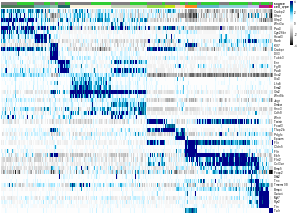

In [18]:
cols   <- c("black", "grey30", "grey60", "grey75", "grey90", "white", "#ccf2ff", "#99e5ff", "deepskyblue3", "deepskyblue4","blue4")
my_pal <- colorRampPalette(cols)(100)
brks   <- seq(-4, 4, length.out = length(my_pal) + 1)

show_fig("./figs/final_pdfs/marker_htmp_6.pdf", draw = pheatmap::pheatmap(
  marker_heatmap,     
  cluster_cols = FALSE,
  cluster_rows = FALSE,
  color = my_pal, breaks = brks,
  annotation_col = annotation_col,
  annotation_colors = annotation_colors,
  annotation_legend = FALSE,
  show_colnames = FALSE,
  na_col = "grey90",
    width = 14, height = 10,
    fontsize = 10
))

Writes **Fig. 6c** to `figs/final_pdfs/marker_htmp_6.pdf`.

### Fig. 6b: cell-state composition

- **6b**: share of each genotype's cells in each cell state

Each cell takes its metacell's state; unannotated, "TBD" and Megakaryocytes are dropped. Host and Dnmt-DKO each sum to 100%; host bars use a darker shade.
- Needs `annotation_col` and `ct_levels` from section "Fig. 6c", so run that section first.

In [19]:
cells = read_h5ad("./data/dnmt_dko_brain_combined_cells.h5ad")

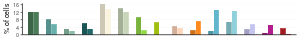

In [20]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(tibble)

cell_type_cols <- mod_e95$colors_e95
cell_type_cols = cell_type_cols[names(cell_type_cols) != "Megakaryocytes"]

host_label <- "host"
ko_label   <- "dko"

df <- cells$obs %>%
  mutate(cell_id = row_number()) %>%
  select(cell_id, source, metacell_name) %>%
  left_join((annotation_col %>% rownames_to_column("metacell_name") %>% select(metacell_name, cell_type)), by = "metacell_name") %>%
  filter(!is.na(cell_type), cell_type != "TBD", cell_type != "Megakaryocytes") %>%
  mutate(source = factor(source, levels = c(host_label, ko_label))) %>%
  count(source, cell_type, name = "n") %>%
  # add missing (source, cell_type) combos with n = 0
  complete(
    source,
    cell_type = factor(names(cell_type_cols), levels = names(cell_type_cols)),
    fill = list(n = 0)
  ) %>%
  group_by(source) %>%
  mutate(f = 100 * n / sum(n)) %>%
  ungroup() %>%
  # compute final per-row fill color (robust; no key/manual scale needed)
  mutate(
    base_col = unname(cell_type_cols[as.character(cell_type)]),
    fill_col = ifelse(source == host_label, darken_hex(base_col, 0.82), base_col),
    cell_type = factor(cell_type, ct_levels)
  )

options(repr.plot.width = 15, repr.plot.height = 2)

p_comp = ggplot(df, aes(x = cell_type, y = f, fill = fill_col)) +
  geom_col(
    width = 0.6,
    position = position_dodge(width = 0.6),
    color = "white",
    linewidth = 0.3
  ) +
  scale_fill_identity() +
  scale_y_continuous(expand = expansion(mult = c(0, 0.01))) +
  labs(x = NULL, y = "% of cells") +
  theme_classic(base_size = 25) +
  theme(
    axis.text.x = element_blank(),
    axis.ticks.x = element_blank(),
    panel.grid.major.y = element_line(linewidth = 0.25, color = "grey90")
  )

show_fig("./figs/final_pdfs/composition.pdf", p_comp, height = 2, width = 15)

Writes **Fig. 6b** to `figs/final_pdfs/composition.pdf`.

### ED Fig. 10h: karyotype from ATAC coverage

- **ED10h**: log2 ratio of normalized Dnmt-DKO to host ATAC coverage along the genome; trisomic chromosome in red

Steps:
- Sums `embdnmt.brain_e95_dko.marginal` and `embdnmt.brain_e95_host.marginal` in 100 kb windows, autosomes only.
- Divides each track by its mean over windows; plots log2 Dnmt-DKO / host. chr14 is red (trisomic).

Notes:
- Windows are 100 kb.
- The reference is the host.
- Same analysis as `prep/E9.5_marginal_tracks.ipynb`.

In [21]:
library(misha)
library(misha.ext)
library(ggplot2)
library(dplyr)
library(tibble)
library(zoo)

In [22]:
gset_genome("mm10")

In [23]:
mut_track = "embdnmt.brain_e95_dko.marginal"
nm = "DNMT DKO KO E9.5"

wt_track = "embdnmt.brain_e95_host.marginal"

In [24]:
ge =  gextract.left_join(c(mut_track, wt_track), iterator = 1e+5, intervals = gintervals.all())

In [25]:
plot_df = data.frame("chrom" = ge$chrom, "start" = ge$start, 
                     "trend_diff" = log2((ge[,4]/mean(ge[,4], na.rm=T))/(ge[,5]/mean(ge[,5], na.rm=T)))) %>%
    filter(!chrom %in% c("chrX", "chrY", "chrM"))
plot_df$chrom = factor(plot_df$chrom, levels = paste0("chr", 1:19))
plot_df = plot_df %>% arrange(chrom, start) %>% mutate(window = row_number())
chrom_lims = cumsum(plot_df %>% group_by(chrom) %>% summarise(nrow = n()) %>% pull(nrow)) 

plot_df$rollmean <- rollmean(plot_df$trend_diff, k = 500, fill = "e")

In [26]:
chrom_mids = add_mean_to_previous(chrom_lims)
label_df = data.frame("window" = chrom_mids, "label" = levels(plot_df$chrom))

In [27]:
plot_df = plot_df %>% mutate(trisomy = ifelse(chrom %in% c("chr14"), "darkred", "grey50"))

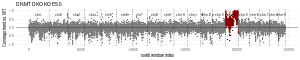

In [28]:
p <- ggplot() + geom_point(data = plot_df, aes(window, trend_diff, color = trisomy), size = 0.5) + theme_minimal(base_size = 15) + 
         geom_hline(yintercept = 0) + ylim(-1,1) + 
         geom_text(data = label_df, aes(x = window, y = 0.8, label = label)) + 
         xlab("100kb window index") + ylab("Coverage trend vs. WT") + ggtitle(nm) + 
         scale_color_identity()

for (i in 1:length(chrom_lims)){
    p = p + geom_vline(xintercept = chrom_lims[i], lty = 2)
}

options(repr.plot.width = 15, repr.plot.height = 3)
show_fig("./figs/final_pdfs/karyo.pdf", p, width = 15, height = 3)

Writes **ED Fig. 10h** to `figs/final_pdfs/karyo.pdf`.

## Fig. 6d and ED Fig. 10c-e: differential expression, Dnmt-DKO vs host

Gene expression of Dnmt-DKO vs host cells per cell state.

### Setup

In [29]:
source(file.path(repo_dir, "E9.5_multiome.Fig6/e95_func.r"))

In [30]:
library(metacell)
library(dplyr)
library(tibble)
library(anndata)
library(tgstat)
library(tidyr)
library(pheatmap)

library(misha.ext)
gset_genome("mm10")
tss = gintervals.load("intervs.global.tss")
mod_e95 <- readRDS(in_path("./data/output/mod_e95.RDS"))
library(ggplot2)

In [31]:
cells = anndata::read_h5ad("./data/dnmt_dko_brain_combined_cells.h5ad")

In [32]:
annot = read.csv("./data/annot_2909.csv", row.names = 1)

In [33]:
cells$obs$reannot_cell_type = annot[cells$obs$metacell_name, "cell_type"]

In [34]:
cell_to_source = setNames(cells$obs$source, rownames(cells$obs))

In [35]:
cell_to_type = setNames(cells$obs$reannot_cell_type, rownames(cells$obs))

In [36]:
umis = t(data.matrix(cells$X))

### Pseudo-bulk expression per cell state

- Cells take their metacell's state (`data/annot_2909.csv`); the 46 "Outliers" cells are dropped.
- UMIs are summed per state, separately for host and Dnmt-DKO.
- States with > 250,000 UMIs in both genotypes are kept and downsampled to 250,000 UMIs (seed 30).
- Expression: log2(UMI fraction + 2e-5). `diff_df` = Dnmt-DKO minus host.

In [37]:
host_cells = names(cell_to_source[which(cell_to_source == "host")])
dko_cells = names(cell_to_source[which(cell_to_source == "dko")])
# cells in the "Outliers" metacell have no annotation; tgs_matrix_tapply fails on NA groups
host_cells = host_cells[!is.na(cell_to_type[host_cells])]
dko_cells = dko_cells[!is.na(cell_to_type[dko_cells])]
umis_host = umis[,host_cells]
umis_dko = umis[,dko_cells]

In [38]:
mhost = t(tgs_matrix_tapply(umis_host, cell_to_type[host_cells], sum))
mko = t(tgs_matrix_tapply(umis_dko, cell_to_type[dko_cells], sum))

In [39]:
cts_both = intersect(colnames(mhost), colnames(mko))

In [40]:
cov = data.frame(row.names = cts_both, "host" = colSums(mhost[,cts_both]), "dko" = colSums(mko[,cts_both]))

In [41]:
min_cov = 250000

In [42]:
cov_f = cov > min_cov
cov_f = rownames(cov_f[apply(cov_f, 1, sum) == 2,])

In [43]:
library(tglkmeans)

mko_ds = downsample_matrix(mko[,cov_f], min_cov, remove_columns = T, seed = 30)
mhost_ds = downsample_matrix(mhost[,cov_f], min_cov, remove_columns = T, seed = 30)

In [44]:
mko_e = t(t(mko_ds)/colSums(mko_ds))
mhost_e = t(t(mhost_ds)/colSums(mhost_ds))

mko_l = log2(2e-5+mko_e)
mhost_l = log2(2e-5+mhost_e)

In [45]:
mko_lf = mko_l - apply(mko_l,1,median)
mhost_lf = mhost_l - apply(mhost_l,1,median)

In [46]:
diff_df = mko_l-mhost_l

ct_order = c("Hindbrain", "Hoxd3+ (spinal cord progenitors)", "Dorsal midbrain", "Midbrain–hindbrain boundary", "Optic vesicle / Telencephalon", "Dmbx1+ (Diencephalon/Mesencephalon)",
             "Neural crest 1", "Neural crest 2", "Epidermis", "Endothelium",
             "Somitic", "Sclerotome", "Bmp4+ Igf2+ / Cranial muscles", "Cardiomyocytes", "Erythroid", "Megakaryocytes")

ct_order = ct_order[ct_order %in% colnames(diff_df)]

### Chi-square test per gene and state

- 2x2 chi-square (gene vs other UMIs, Dnmt-DKO vs host) on the downsampled counts; genes with < 10 UMIs are skipped.
- FDR per state. `sig_gns`: q < 0.05 in any of the six ectoderm states (first six of `ct_order`).

In [47]:
umi_df = full_join(
    mko_ds %>% as.data.frame() %>% rownames_to_column("gene") %>% pivot_longer(-gene, names_to = "cell_type", values_to = "ko") %>%
        group_by(cell_type) %>% mutate(tot_min_ko = sum(ko)-ko) %>% ungroup(),
    mhost_ds %>% as.data.frame() %>% rownames_to_column("gene") %>% pivot_longer(-gene, names_to = "cell_type", values_to = "host") %>%
        group_by(cell_type) %>% mutate(tot_min_host = sum(host)-host) %>% ungroup()
    )

chisq = calc_chisq_pval_per_cell_type(umi_df)

In [48]:
sig_gns = chisq %>% filter(cell_type %in% ct_order[1:6], qval < 0.05) %>% pull(gene) %>% unique()

### ED Fig. 10c: expression correlation between states

- **ED10c**: correlation of pooled expression between E9.5 states; rows Dnmt-DKO, columns host.

Pearson correlation over genes with median-centred expression > 1.5 (log2) in some state. Rows and columns share one Ward clustering order.

In [49]:
annotation_phtmp = distinct(annot[,"cell_type",F])
rownames(annotation_phtmp) = annotation_phtmp$cell_type

annotation_colors = list("cell_type" = deframe(distinct(annot[,c("cell_type", "color"),F])))

In [50]:
annotation_colors = list("cell_type" = mod_e95$colors_e95)

colorscale = c("black", "grey30", "grey60", "grey90", "white", "deepskyblue1", "deepskyblue2", "deepskyblue3", "deepskyblue4")
colors <- colorRampPalette(colorscale)(100)

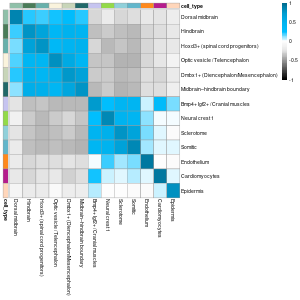

In [51]:
f = apply(cbind(mko_lf, mhost_lf),1,max)>1.5
cross = tgs_cor(mko_lf[f,], mhost_lf[f,])
hc = hclust(tgs_dist(cross), "ward.D2")


options(repr.plot.width = 8, repr.plot.height = 8)
show_fig("./figs/final_pdfs/e95_fidelity_states.pdf", draw = pheatmap::pheatmap(cross[hc$order,hc$order], 
                   cluster_rows = F, cluster_cols = F, 
                   annotation_col = annotation_phtmp, annotation_row = annotation_phtmp,
                   annotation_colors = annotation_colors,
                   annotation_legend = F,
                   width = 8, height = 8,
                   color = colors,
                   breaks = seq(-1, 1, length.out = 101)))

Writes **ED10c** to `figs/final_pdfs/e95_fidelity_states.pdf`.

### ED Fig. 10d: differential expression heatmap

- **ED10d**: log fold-change (DKO vs host) in states with > 250,000 UMIs in both genotypes.

Genes kept:
- |log2 FC| >= 1 in some state,
- host max > -13.5 (log2),
- q < 0.05 in an ectoderm state,
- not on chrX, chrY or chr14 (trisomic in this clone, ED Fig. 10h), and not lateral.

Clustered by k-means (k = 10, seed 30); clusters ordered by the state of their max centre.

In [52]:
diff_thresh = 1
minimal_diff = names(which(apply(diff_df, 1, function(x) {sum(abs(x)>=diff_thresh)>0})))#|sum(x<=(-diff_thresh))>0})))
minimal_host_expr = names(which(apply(mhost_l, 1, max) > -13.5))

In [53]:
htmp_gns = intersect(intersect(minimal_diff, minimal_host_expr), sig_gns)
htmp_gns = tss %>% filter(geneSymbol %in% htmp_gns) %>% select(geneSymbol, chrom) %>% distinct() %>% filter(!(chrom %in% c("chrX", "chrY", "chr14"))) %>% pull(geneSymbol)

library(anndata)
mcells = anndata::read_h5ad("./data/dnmt_dko_brain_combined_cells.h5ad")
lateral_genes = mcells$var_names[mcells$var$lateral_gene]

htmp_gns = htmp_gns[!htmp_gns %in% lateral_genes]
message(length(htmp_gns), " genes selected.")

In [54]:
highlight_gns = c("Wnt1", "Wnt3a", "Jag1", "Bmp5", 
                  "Dkk2", "Sfrp2", "Pax3", "Pax2", 
                  "Eno2", "Cdh10", "Nkx6-2", "Ano3", "Tmem108",
                  "Sfrp2", "Tfap2b", "Myl7", "Actc1",
                  "Cyp26b1", "Crabp1", "Crabp2", "Rarb", "Lmx1a",
                  "Klf7", "Slit1", "Slit2", "Sox5", "Ets2", "Lhx5", "Epha3",
                  "Foxp2", "Sox6", "Myl4", "Col2a1")

highlight_gns = highlight_gns[highlight_gns %in% sig_gns]

In [55]:
mat = diff_df[htmp_gns, ct_order]

km <- TGL_kmeans_tidy(mat,
    k = 10,
    metric = "euclid",
    verbose = FALSE,
    seed = 30
)

In [56]:
gns = km$cluster %>% filter(clust == 4) %>% pull(id)

In [57]:
max_col = apply(km$centers[,2:ncol(km$centers)], 1, which.max)
names(max_col) = km$centers$clust

clust_order = names(sort(max_col))
gn_to_clust = km$cluster %>% arrange(match(clust, clust_order))

gn_order = gn_to_clust %>% pull(id)
cl <- gn_to_clust$clust
gaps_row <- cumsum(rle(cl)$lengths)
gaps_row <- gaps_row[-length(gaps_row)]

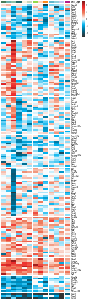

In [58]:
options(repr.plot.height = 17, repr.plot.width = 5)

cor_mat <- cor(t(mat), use = "pairwise.complete.obs")
dist_mat <- as.dist(1 - cor_mat)

show_fig("./figs/final_pdfs/dge_full.pdf", draw = pheatmap(
  mat[gn_order,],
  cluster_rows = FALSE,
  cluster_cols = FALSE,
    annotation_col = data.frame(row.names = names(annotation_colors$cell_type), cell_type = names(annotation_colors$cell_type)),
    annotation_colors = annotation_colors,
    annotation_legend = F,
    show_colnames = F,
    show_rownames = T,
  scale = "none",
    gaps_col = c(6,9,12),
    gaps_row = gaps_row,
    fontsize = 8,
        height = 17, width = 5,
  color = colorRampPalette(c("grey20", "deepskyblue4", "deepskyblue2", "white",
  "salmon2", "firebrick2", "firebrick4"))(100),
  breaks = seq(-2.5, 2.5, length.out = 101)
))

Writes **ED10d** to `figs/final_pdfs/dge_full.pdf`.

### Fig. 6d: selected genes in ectoderm states

- **6d**: expression of 16 selected genes, host vs Dnmt-DKO, in six ectoderm states.

`plot_brain_expr()` draws host and Dnmt-DKO log2 expression bars per state, starting at log2(2e-5). Asterisks are chi-square q-values (`*` < 0.05, `**` < 0.01, `***` < 0.001, NS). States failing the coverage filter are dropped.

In [59]:
highlight_cell_type = c("Hindbrain", "Hoxd3+ (spinal cord progenitors)", "Dorsal midbrain", "Midbrain–hindbrain boundary", "Optic vesicle / Telencephalon", "Dmbx1+ (Diencephalon/Mesencephalon)")

highlight_gns = c("Wnt1", "Wnt3a", "Bmp5", "Dkk2", "Crabp2", "Rarb", "Klf7", "Foxp2", "Pax3", "Tmem108", "Tfap2b", "Crabp1", "Jag1", "Sfrp2", "Ano3", "Lhx5")
plot_list_6d = vector("list", length = length(highlight_gns)) 
i = 1
for (highlight_gn in highlight_gns){
    p_gn = plot_brain_expr(highlight_gn, highlight_cell_type)
    plot_list_6d[[i]] = p_gn
    i = i + 1
}

Writes **Fig. 6d** to `figs/final_pdfs/6C.pdf` (old panel numbering).

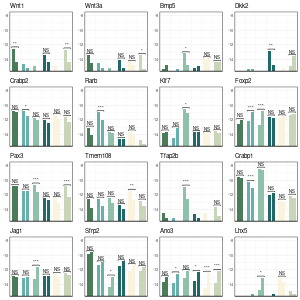

In [60]:
options(repr.plot.height = 8, repr.plot.width = 8)
library(gridExtra)

show_fig("./figs/final_pdfs/6C.pdf", width = 8, height = 8, draw = gridExtra::grid.arrange(grobs = plot_list_6d, ncol = 4))

### ED Fig. 10e: germline genes

- **ED10e**: twelve germline genes across states, Dnmt-DKO vs host.

Plotted in all states passing the coverage filter, without significance marks, y-axis capped at -14 (log2).

In [61]:
all_cell_types = c(highlight_cell_type, 'Neural crest 1', 'Neural crest 2', 'Epidermis', 'Endothelium', 'Somitic', 'Sclerotome', 'Bmp4+ Igf2+ / Cranial muscles', 'Cardiomyocytes', 'Erythroid')

In [62]:
f = all_cell_types %in% colnames(mko_l)
all_cell_types[!f]
colnames(mko_l)


In [63]:
library(ggplot2)
germline_gns = c("Asz1", "Fkbp6", "Tex19.1", "Rpl10l", "Gpat2", "Mov10l1", "Ddx4", "Hormad1", "Gtsf1", "Piwil2", "Topaz1", "Mael")
plot_list_germ = vector("list", length = length(germline_gns)) 
i = 1
for (highlight_gn in germline_gns){
    p_gn = plot_brain_expr(highlight_gn, all_cell_types, lower_y = log2(2e-5), upper_y = -14, plot_sig = F)
    plot_list_germ[[i]] = p_gn
    i = i + 1
}

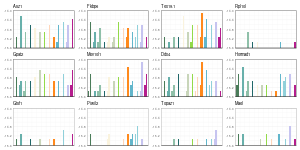

In [64]:
library(patchwork)
options(repr.plot.width = 12, repr.plot.height = 6)

p_all <- wrap_plots(plot_list_germ, ncol = 4, nrow = 3)

show_fig("./figs/final_pdfs/germline_e95_barplots.pdf", p_all, width = 12, height = 6)

Writes **ED10e** to `figs/final_pdfs/germline_e95_barplots.pdf`.

## Fig. 6e-g and ED Fig. 10f, g: CRE accessibility clusters

Clusters CREs by accessibility across pooled E9.5 and gastrulation cell states, then compares host and Dnmt-DKO accessibility per cluster group, stratified by CpG content.

### Setup

In [65]:
# Run the within-cluster hclust of the CRE clustering in one process: its forked workers hang
# once the earlier parts have started Python (anndata). Results are the same.
options(tglkmeans.parallel = FALSE)

library(dplyr)
library(tibble)
library(ggplot2)
library(patchwork)

In [66]:
setwd(embdnmt_dir)
source(file.path(repo_dir, "scripts/lineage_peaks_func.r"))
source(file.path(repo_dir, "scripts/ATAC_preprocessing.r"))
mod_prev = readRDS(in_path(paste0(embdnmt_dir, "/data/output/mod.RDS")))

setwd(paste0(embdnmt_dir, "/revision_e95"))
source(file.path(repo_dir, "E9.5_multiome.Fig6/Fig6_func.r")) # Revised code + some new code for Fig6

Loads the E9.5 ATAC model `mod_e95` from its cache (`data/output/mod_e95.RDS`); `init_e95()` in `E9.5_multiome.Fig6/Fig6_func.r` builds it (rebuild off, `if (0)`).
- Peaks: called on the combined E9.5 + gastrulation track (`embdnmt.brain_e95_dko.marginal_plus_gastr`), split into TSS peaks (within 5 kb of a TSS) and CREs (`cre_peaks`).
- chr14 (trisomic in this clone) is left out of the peak set; coverage is not karyotype-corrected.
- `mod_e95$cmat`: per peak and pooled state, log2 share of total peak coverage (pseudocount 1e-6), host (`.host`) and Dnmt-DKO (`.dko`).
- E9.5 states: five ectoderm (hindbrain, Hoxd3+ SCP, MHB, optic vesicle/telencephalon, Dmbx1+ di/mesencephalon), three mesoderm (somitic, sclerotome, Bmp4+ Igf2+ cranial muscles). Neural crest 1 is only in `cmat_nc`.
- Gastrulation states (from `mod.RDS`, WT vs Dnmt-DKO): rostral neural plate (`rnp`), ExE mesoderm, allantois (`ac_prog`), hematoendothelial progenitors, late nascent mesoderm, cardiopharyngeal mesoderm, surface ectoderm, gut.

In [67]:
source(file.path(repo_dir, "E9.5_multiome.Fig6/Fig6_func.r")) # Revised code + some new code for Fig6
if (0){
    mod_e95 <- init_e95(mod_prev = mod_prev, force_cmat_redo = T)
    saveRDS(mod_e95, out_path("./data/output/mod_e95.RDS"))
}

mod_e95 <- readRDS(in_path("./data/output/mod_e95.RDS"))

### Cell-state legend

Writes the colour legend (no Megakaryocytes) to `figs/final_pdfs/legend_e95.png`. Not a lettered panel.

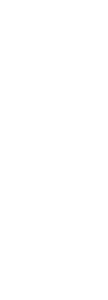

In [68]:
library(ggplot2)
library(grid)
library(stringr)
library(cowplot)

# named vector: colors
names(mod_e95$colors_e95) <- gsub("\u2013", "-", names(mod_e95$colors_e95))
cols <- mod_e95$colors_e95[names(mod_e95$colors_e95) != "Megakaryocytes"]

# wrap (NO extra blank lines)
labs_wrapped <- str_wrap(names(cols), width = 18)

# dummy data just to create the legend
df_leg <- data.frame(
  x = seq_along(cols),
  y = 1,
  cell_state = factor(names(cols), levels = names(cols))
)

p_leg <- ggplot(df_leg, aes(x, y, color = cell_state)) +
  geom_point(size = 4) +
  scale_color_manual(values = cols, labels = labs_wrapped) +
  guides(color = guide_legend(
    title = NULL,
    byrow = TRUE,
    keyheight = unit(7, "mm"),   # <-- space per entry (increase to 8–10mm)
    keywidth  = unit(6, "mm"),
    override.aes = list(size = 5)
  )) +
  theme_void(base_size = 16) +
  theme(
    legend.position = "left",
    legend.spacing.y = unit(3, "mm"),     # <-- extra gap BETWEEN entries
    legend.text = element_text(size = 18),
    plot.margin = margin(0, 0, 0, 0),
    legend.margin = margin(0, 0, 0, 0)
  )

lg <- cowplot::get_legend(p_leg)

dir.create(out_path("./figs/final_pdfs"), recursive = TRUE, showWarnings = FALSE)

# Save ONLY the legend (no huge whitespace)
show_fig("./figs/final_pdfs/legend_e95.png", cowplot::ggdraw(lg), width = 3.6, height = 10, units = "in", dpi = 300, bg = "white")


### Fig. 6e and ED Fig. 10f: CRE clusters

- **6e**: accessibility heatmaps of selected cluster groups, grouped by lineage and stage
- **ED10f**: all clusters of CREs with large Dnmt-DKO vs host differences

`plot_crecl_htmp()` (`E9.5_multiome.Fig6/Fig6_func.r`):
- Keeps CREs with |Dnmt-DKO - host| >= 1.5 (log2) in at least one state and maximum >= -17.5.
- k-means (`TGL_kmeans_tidy`, k = 16, seed 30); clusters ordered by hierarchical clustering of centres; heatmap shows a rolling mean of 20 CREs (display only).
- Saves assignments, colours and matrices to `data/output/cre_cluster_*.RDS`.

Notes:
- The filter is absolute, so both gains and losses are kept.
- Later sections read the original `./data/output/cre_cluster_assignments.RDS` (the published clustering), or the copy written here with `use_regenerated_inputs = TRUE` (`paths.R`).

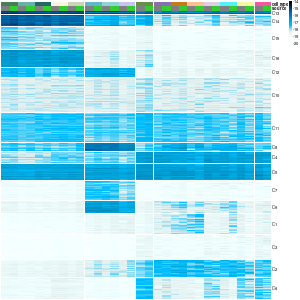

In [69]:
source(file.path(repo_dir, "E9.5_multiome.Fig6/Fig6_func.r")) # Revised code + some new code for Fig6
plot_crecl_htmp(mod_e95, cmat_name = "cmat", peak_subset = "cre_peaks", n_clust = 16, lower = -20, upper = -14, diff_thresh = 1.5, nonactive_thresh = -17.5, 
                gaps_col = c(10, 16, 18, 30), name = "cre")

Writes the full clustered heatmap to `figs/crecl/cre_crecls.png` (all clusters, unsplit).

#### CpG content of the clustered CREs

`cg_max` = max of `seq.CG_500_mean_new` over each CRE, binned into <0.02, 0.02-0.04, >0.04. Stored in `crecl_peaks` (no cluster column).

In [70]:
cluster_assignment = readRDS(in_path("./data/output/cre_cluster_assignments.RDS"))
cre_df = mod_e95$cre_peaks %>% left_join(cluster_assignment %>% rownames_to_column("peak_name"))
cre_df = cre_df[,c("chrom", "start", "end", "peak_name", "cluster")]

gvtrack.create("cg_max", "seq.CG_500_mean_new", "max")
e_cg = gextract(c("cg_max"), intervals=cre_df, iterator=cre_df, colnames=c("cg_max"))
cre_df$cg_max = e_cg[,4]

bin_breaks <- c(-Inf, 0.02, 0.04, Inf)
bin_labels <- c("<0.02","0.02-0.04", ">0.04")

cg_df <- cre_df %>% mutate(
    bin = cut(cg_max,
              breaks = bin_breaks,
              labels = bin_labels,
              right = FALSE,           # intervals like [0.02,0.04)
              include.lowest = TRUE))

crecl_peaks = cluster_assignment %>% rownames_to_column("peak_name") %>% left_join(mod_e95$cre_peaks) %>%
    left_join(cg_df[,c("chrom", "start", "end", "peak_name", "cg_max", "bin")], by=c("chrom", "start", "end", "peak_name")) %>%
    select(chrom, start, end, peak_name, cg_max, bin) %>% rename(cg_bin = bin)

#### Fig. 6e: heatmaps of selected cluster groups

`plot_crecl_clusters()` (`E9.5_multiome.Fig6/Fig6_func.r`) draws the requested clusters from the saved smoothed matrix, gastrulation states first, one PDF per call.
- Late ectoderm: C14, C15, C16
- Late mesoderm: C12, C8, C7, C9
- Gastrulation: C4
- Gastrulation ectoderm: C6
- Gastrulation mesoderm: C2

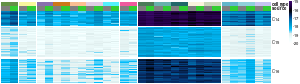

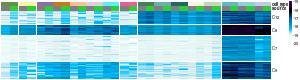

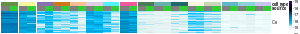

In [71]:
source(file.path(repo_dir, "E9.5_multiome.Fig6/Fig6_func.r"))

p_le <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = c("14", "15", "16"),
    figs_dir = "./figs/final_pdfs"
)

p_lm <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = c("12", "8", "7", "9"),
    figs_dir = "./figs/final_pdfs"
)

p_g <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = c("4"),
    figs_dir = "./figs/final_pdfs"
)

p_ge <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = c("6"),
    figs_dir = "./figs/final_pdfs"
)

p_gm <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = c("2"),
    figs_dir = "./figs/final_pdfs"
)

**Fig. 6e** outputs in `figs/final_pdfs/`:
- `cre_clusters_C14_C15_C16.pdf` (late ectoderm)
- `cre_clusters_C12_C8_C7_C9.pdf` (late mesoderm)
- `cre_clusters_C4.pdf`, `cre_clusters_C6.pdf`, `cre_clusters_C2.pdf` (gastrulation groups)
- `cre_colorscale_new.pdf` (colour scale)

Duplicate of the late mesoderm call, written to `figs/final_pdfs/final_countdown/`.

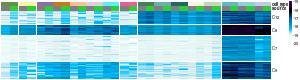

In [72]:
p_lm <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = c("12", "8", "7", "9"),
    figs_dir = "./figs/final_pdfs/final_countdown/"
)

#### ED Fig. 10f: remaining and all clusters

Outputs in `figs/final_pdfs/`:
- `cre_clusters_C13_C10_C11_C5_C1_C3.pdf`: the six clusters not in Fig. 6e
- `cre_clusters_C6_C4_C2_C14_C15_C16_C12_C8_C7_C9.pdf`: the ten Fig. 6e clusters together
- `cre_clusters_ALL.pdf`: all 16 clusters (**ED10f**)

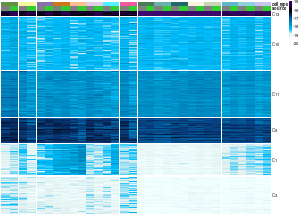

In [73]:
other_cs = setdiff(levels(cluster_assignment$cluster), c("6", "4", "2", "14", "15", "16", "12", "8", "7", "9"))
p_other <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = other_cs,
    figs_dir = "./figs/final_pdfs"
)

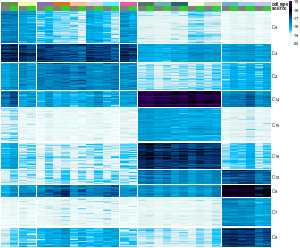

In [74]:
source(file.path(repo_dir, "E9.5_multiome.Fig6/Fig6_func.r"))

p_highlight <- plot_crecl_clusters(
    name = "cre", 
    clusters_keep = c("6", "4", "2",    "14", "15", "16",    "12", "8", "7", "9"),
    figs_dir = "./figs/final_pdfs",
    keep_cluster_order = TRUE
)

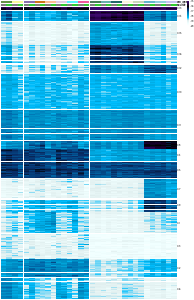

In [75]:
plot_crecl_clusters(
    name = "cre", 
    figs_dir = "./figs/final_pdfs",
    keep_cluster_order = TRUE
)

### ED Fig. 10g: host vs Dnmt-DKO scatters

- **ED10g**: Dnmt-DKO vs host accessibility per CRE category (rows) and state group (columns); dashed lines and percentages mark two-fold changes

`plot_clusters_host_vs_ko_4panels()` averages `cmat` per CRE over each state group, host and Dnmt-DKO separately:
- Late ectoderm: the five E9.5 ectoderm states
- Late mesoderm: the three E9.5 mesoderm states
- Early ectoderm: rostral neural plate
- Early mesoderm: ExE mesoderm, allantois, hematoendothelial progenitors, late nascent mesoderm, cardiopharyngeal mesoderm

Caveats:
- Groups are picked by position in `types_all`, so its order matters.
- `peaks_df` is unused.

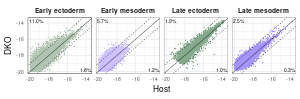

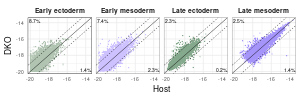

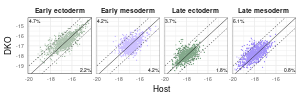

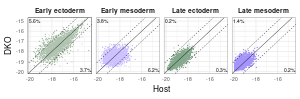

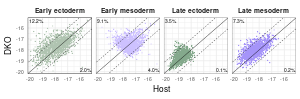

In [76]:
types_all <- list(
  Hindbrain=list(host_col="Hindbrain.host",ko_col="Hindbrain.dko"),
  Hoxd3_spinal_cord_progenitors=list(host_col="Hoxd3_spinal_cord_progenitors.host",ko_col="Hoxd3_spinal_cord_progenitors.dko"),
  Midbrain_hindbrain_boundary=list(host_col="Midbrain_hindbrain_boundary.host",ko_col="Midbrain_hindbrain_boundary.dko"),
  Optic_vesicle_Telencephalon=list(host_col="Optic_vesicle_Telencephalon.host",ko_col="Optic_vesicle_Telencephalon.dko"),
  Dmbx1_Diencephalon_Mesencephalon=list(host_col="Dmbx1_Diencephalon_Mesencephalon.host",ko_col="Dmbx1_Diencephalon_Mesencephalon.dko"),
  Somitic=list(host_col="Somitic.host",ko_col="Somitic.dko"),
  Sclerotome=list(host_col="Sclerotome.host",ko_col="Sclerotome.dko"),
  Bmp4_Igf2_Cranial_muscles=list(host_col="Bmp4_Igf2_Cranial_muscles.host",ko_col="Bmp4_Igf2_Cranial_muscles.dko"),
  rnp=list(host_col="rnp.host",ko_col="rnp.dko"),
  exe_meso=list(host_col="exe_meso.host",ko_col="exe_meso.dko"),
  ac_prog=list(host_col="ac_prog.host",ko_col="ac_prog.dko"),
  haem_prog=list(host_col="haem_prog.host",ko_col="haem_prog.dko"),
  lnm=list(host_col="lnm.host",ko_col="lnm.dko"),
  card_meso=list(host_col="card_meso.host",ko_col="card_meso.dko"),
  se=list(host_col="se.host",ko_col="se.dko"),
  gut=list(host_col="gut.host",ko_col="gut.dko")
)

options(repr.plot.height = 3.3, repr.plot.width = 10)
p_le <- plot_clusters_host_vs_ko_4panels(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("14", "15", "16"),
    types_all = types_all
)

p_lm <- plot_clusters_host_vs_ko_4panels(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("12", "8", "7", "9"),
    types_all = types_all
)

p_g <- plot_clusters_host_vs_ko_4panels(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("4"),
    types_all = types_all
)

p_ge <- plot_clusters_host_vs_ko_4panels(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("6"),
    types_all = types_all
)

p_gm <- plot_clusters_host_vs_ko_4panels(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("2"),
    types_all = types_all
)

show_fig("./figs/final_pdfs/late_ecto_peaks_scatters.pdf", p_le, width = 10, height = 3.3)
show_fig("./figs/final_pdfs/late_meso_peaks_scatters.pdf", p_lm, width = 10, height = 3.3)
show_fig("./figs/final_pdfs/gastru_peaks_scatters.pdf", p_g, width = 10, height = 3.3)
show_fig("./figs/final_pdfs/gastru_ecto_peaks_scatters.pdf", p_ge, width = 10, height = 3.3)
show_fig("./figs/final_pdfs/gastru_meso_peaks_scatters.pdf", p_gm, width = 10, height = 3.3)

One row of **ED10g** per file in `figs/final_pdfs/`: `late_ecto_peaks_scatters.pdf`, `late_meso_peaks_scatters.pdf`, `gastru_peaks_scatters.pdf`, `gastru_ecto_peaks_scatters.pdf`, `gastru_meso_peaks_scatters.pdf`.

### Fig. 6f, g: CpG content and accessibility per cluster group

- **6f**: CpG bin composition per cluster group
- **6g**: host vs Dnmt-DKO accessibility per CpG bin and state group, paired Wilcoxon

In [77]:
cluster = readRDS(in_path("./data/output/cre_cluster_assignments.RDS"))
peaks_per_cluster = as.data.frame(table(cluster))
message("le: ", peaks_per_cluster %>% filter(cluster %in% c("14", "15", "16")) %>% summarize(sum(Freq)) %>% pull(1))
message("lm: ", peaks_per_cluster %>% filter(cluster %in% c("12", "8", "7", "9")) %>% summarize(sum(Freq)) %>% pull(1))
message("g: ", peaks_per_cluster %>% filter(cluster %in% c("4")) %>% summarize(sum(Freq)) %>% pull(1))
message("ge: ", peaks_per_cluster %>% filter(cluster %in% c("4")) %>% summarize(sum(Freq)) %>% pull(1))
message("gm: ", peaks_per_cluster %>% filter(cluster %in% c("2")) %>% summarize(sum(Freq)) %>% pull(1))

`plot_paired_box_by_cgbin()`, same state groups as the scatters:
- Left bar: fraction of CREs per CpG bin (**6f**).
- Boxes: host vs Dnmt-DKO per CpG bin and state group (**6g**); paired Wilcoxon per CRE, BH-adjusted within a cluster group; asterisks at p <= 0.05, 0.01, 0.001.
- y-axis clipped to -20 to -14; brackets at a fixed height.

In [78]:
options(repr.plot.height = 4, repr.plot.width = 10)
p_le <- plot_paired_box_by_cgbin(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("14", "15", "16"),
    types_all = types_all
)

p_lm <- plot_paired_box_by_cgbin(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("12", "8", "7", "9"),
    types_all = types_all
)

p_g <- plot_paired_box_by_cgbin(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("4"),
    types_all = types_all
)

p_ge <- plot_paired_box_by_cgbin(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("6"),
    types_all = types_all
)

p_gm <- plot_paired_box_by_cgbin(
    cmat = mod_e95$cmat,
    peaks_df = crecl_peaks,
    name = "cre", 
    clusters_keep = c("2"),
    types_all = types_all
)

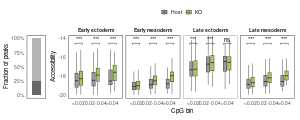

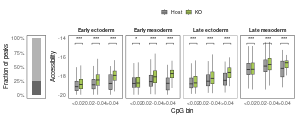

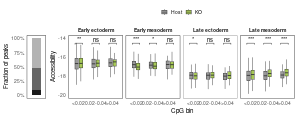

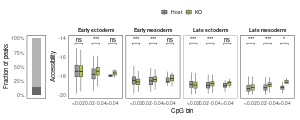

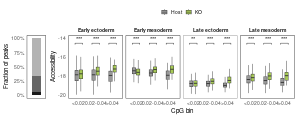

In [79]:
show_fig("./figs/final_pdfs/late_ecto_peaks_bars.pdf", p_le, width = 10, height = 4)
show_fig("./figs/final_pdfs/late_meso_peaks_bars.pdf", p_lm, width = 10, height = 4)
show_fig("./figs/final_pdfs/gastru_peaks_bars.pdf", p_g, width = 10, height = 4)
show_fig("./figs/final_pdfs/gastru_ecto_peaks_bars.pdf", p_ge, width = 10, height = 4)
show_fig("./figs/final_pdfs/gastru_meso_peaks_bars.pdf", p_gm, width = 10, height = 4)

**Fig. 6f, g** outputs, one cluster group per file in `figs/final_pdfs/`: `late_ecto_peaks_bars.pdf`, `late_meso_peaks_bars.pdf`, `gastru_peaks_bars.pdf`, `gastru_ecto_peaks_bars.pdf`, `gastru_meso_peaks_bars.pdf`.